# 03 — Scenario, anchor, and transition lab

This notebook studies the general rules on the football pitch. It does not hand-label frames and it does not change the submission file.

The questions are:

1. Where is the ball, and which players are geometrically close?
2. Which scenario does the evidence support: controlled, pressured, flight, contested, occluded, dead ball, or reception candidate?
3. Where does the anchor hierarchy find reliable H/A evidence?
4. If anchors differ, where does the transition evidence appear?

The pitch view shows the local geometry. The timeline below it shows the scenario and anchor logic over the same frame window.

## Method

`build_engineered_features()` calculates every supplied and engineered signal once. The visualisation then consumes those columns; it does not invent a label from the plot.

- solid blue = observed ball path;
- orange dotted line = missing-ball bridge;
- purple dashed line = nearest-player geometry;
- timeline dots = nearest-team observation and selected anchor;
- coloured lower dots = scenario context;
- red triangles = transition anchors.

A Smart Tagging event can open a scenario window, but ATD geometry and controlled-reception evidence decide whether an H/A transition is allowed.

In [1]:
# Purpose: build the canonical feature table and expose its evidence columns.
from pathlib import Path
import sys
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.cwd().resolve()
while not (ROOT / 'possession').exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))
from possession.calculations.features import build_engineered_features
from possession.baseline_pipeline import ClosestTeamRuleModel, slot_team_map
from possession.calculations.plotting import plot_evidence_window, select_evidence_window
from possession.temporal_rules import load_rules
from games import asset_paths

rules = load_rules()
model = ClosestTeamRuleModel()
features = build_engineered_features(model=model, rules=rules)
team_by_slot = slot_team_map(asset_paths(model.game, model.data_dir, source='tactical')['atd_meta'])

# Public ground truth is plotted as an audit strip only; it is never used to build features.
gt_path = ROOT / 'evaluation' / 'gt' / 'BAR-ATH_possession_gt_public.csv'
gt_by_frame = (pd.read_csv(gt_path).set_index('frame')['label'] if gt_path.exists() else None)
print('public ground truth:', 'available for comparison' if gt_by_frame is not None else 'not available in this checkout')
print('feature table:', features.shape)
print('scenario counts:')
print(features['scenario_context'].value_counts(dropna=False).to_string())
print('anchor sources:')
print(features['selected_anchor_source'].value_counts(dropna=False).to_string())
smart_columns = [c for c in features.columns if c.startswith('smart_') and c not in {'smart_restart_type'}]
print('Smart Tagging context flags:')
print(features[smart_columns].select_dtypes(include='number').sum().sort_values(ascending=False).head(15).to_string())
print('Restart types:')
print(features['smart_restart_type'].value_counts(dropna=True).to_string())


public ground truth: available for comparison
feature table: (199319, 439)
scenario counts:
scenario_context
OCCLUDED                 71724
BALL_IN_FLIGHT           27831
RESTART_LIVE_BOUNDARY    22378
DEAD                     17558
UNKNOWN                  16051
CONTROLLED               15781
CONTESTED                10455
PRESSURED_CONTROL        10188
RECEPTION_CANDIDATE       5812
TRANSITION_CANDIDATE      1539
RECEPTION                    2
anchor sources:
selected_anchor_source
NO_ANCHOR                      185637
pressure_anchor_team             8986
anchor_team                      2424
restart_control_anchor_team      2272
Smart Tagging context flags:
smart_event_count    409696
Restart types:
smart_restart_type
Throw-in                 21000
Corner Kick               9230
Goal Kick                 8671
Free Kick                 4380
Kick Off (After Goal)      504
Kick Off (Start)           252


## Case A — ball missing between observed anchors

We first inspect a missing-ball interval. The dotted bridge is only a geometric audit: it asks whether the endpoints and nearby player movement are coherent. It is not permission to force a possession switch.
The lower timeline includes the public ground-truth H/A bar when the evaluation file is present. It is a post-hoc comparison, not a labelling input.


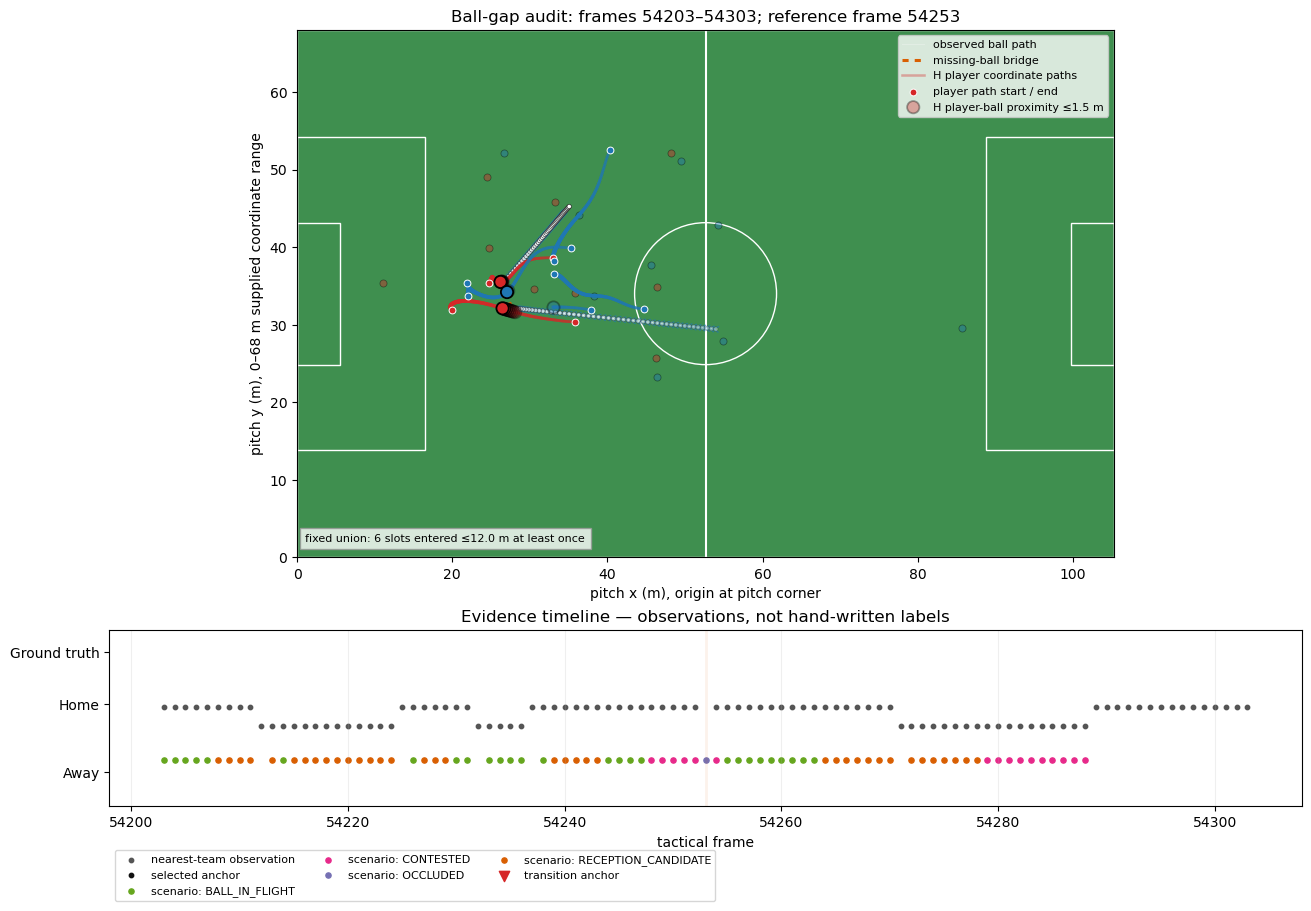

In [2]:
# Purpose: show the ball gap, player geometry, and scenario timeline.
window = select_evidence_window(features, kind='missing_ball', context_frames=50)
if window is None:
    print('No internal missing-ball window was found.')
else:
    fig, axes = plot_evidence_window(
        features, *window, team_by_slot=team_by_slot, ground_truth=gt_by_frame
    )
    plt.show()


## Case B — candidate transition and anchor agreement

A nearest-player change is only an observation. The transition rule asks for a previous anchor, a later anchor from the other team, and reception evidence in the bounded interval. This plot lets us inspect whether those pieces really agree.

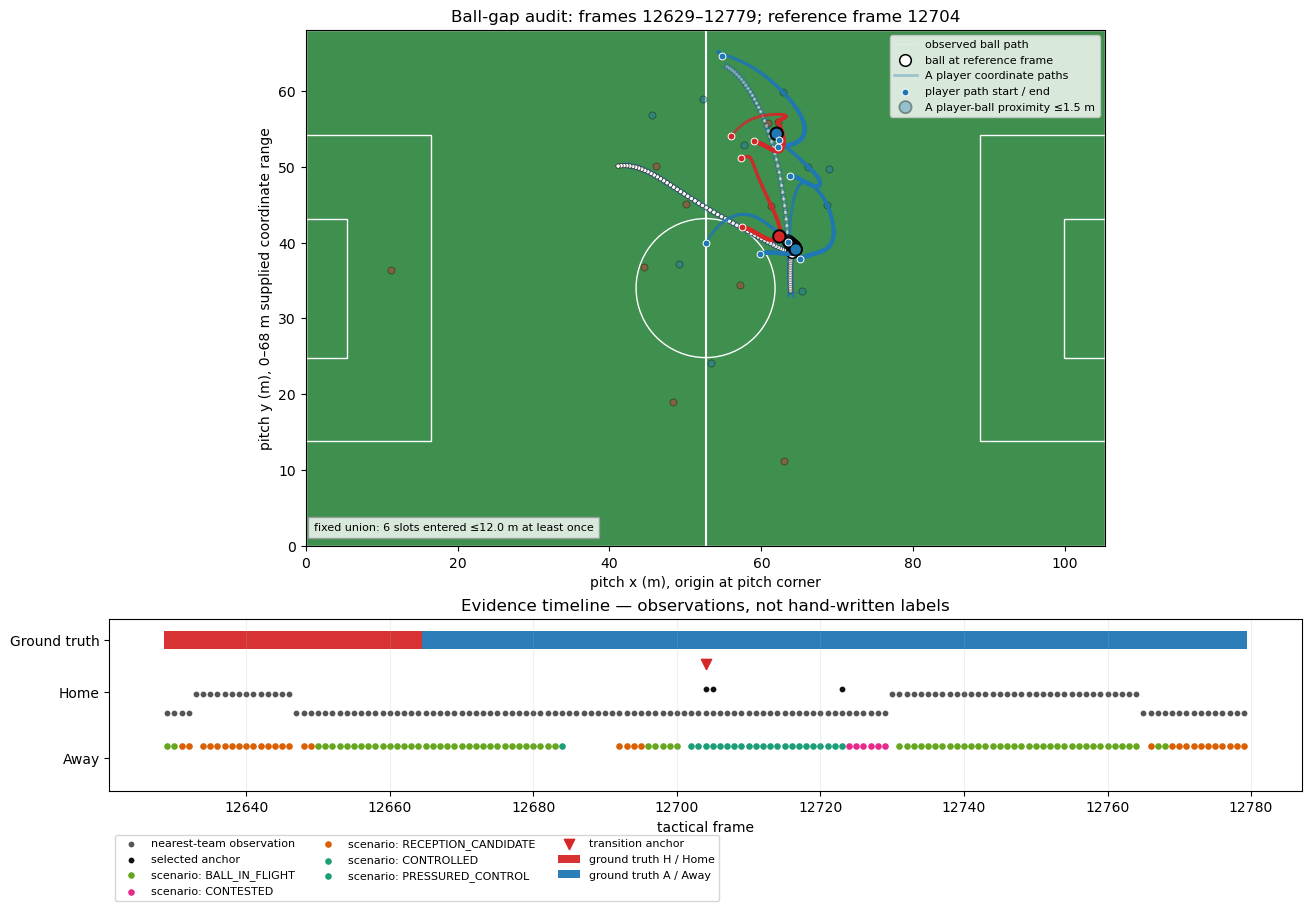

In [3]:
# Purpose: inspect the first algorithmically detected transition window.
window = select_evidence_window(features, kind='transition', context_frames=75)
if window is None:
    print('No algorithmic transition anchor was found in this run.')
else:
    fig, axes = plot_evidence_window(
        features, *window, team_by_slot=team_by_slot, ground_truth=gt_by_frame
    )
    plt.show()


## Findings to carry into the pipeline

- A player being closest to the ball is useful for generating evidence, but not sufficient for H/A.
- Missing-ball bridges need both endpoint geometry and local player support; otherwise preserve the supported state rather than inventing a switch.
- Scenario context explains why nearest-player evidence may be unreliable. It does not itself decide the label.
- A transition is strongest when the later controlled receiver agrees with the candidate reception and the anchor hierarchy.
- These plots operate on the feature table and frame ranges, not hand-selected football incidents, so the same notebook can be run on another match with the same data schema.